In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
import glob
import math

In [2]:
def plot_images(images, cols=4, titles=None, figsize_per_col=4, figsize_per_row=4, ):
    """
    Plots a list of OpenCV images (numpy arrays) in a grid.
    
    :param images: List of images in OpenCV format (BGR or Grayscale).
    :param cols: Number of columns in the grid.
    :param titles: Optional list of titles corresponding to each image.
    :param figsize_per_col: Width allocated per column in inches.
    :param figsize_per_row: Height allocated per row in inches.
    """
    n = len(images)
    if n == 0:
        print("No images to display.")
        return
    cols = min(cols, n)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * figsize_per_col, rows * figsize_per_row))
    
    # Ensure axes is always a flat list/iterable
    if n == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    for idx, img in enumerate(images):
        ax = axes[idx]
        
        # Grayscale vs BGR conversion
        if len(img.shape) == 2:
            ax.imshow(img, cmap='gray')
        elif img.shape[2] == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        elif img.shape[2] == 4:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGRA2RGBA))
        else:
            ax.imshow(img)
        if titles and idx < len(titles):
            ax.set_title(titles[idx])
            
        ax.axis('off')
    # Turn off any unused subplots
    for idx in range(n, len(axes)):
        axes[idx].axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
samples_list = glob.glob("temp/samples_cellphone/*.jpg")

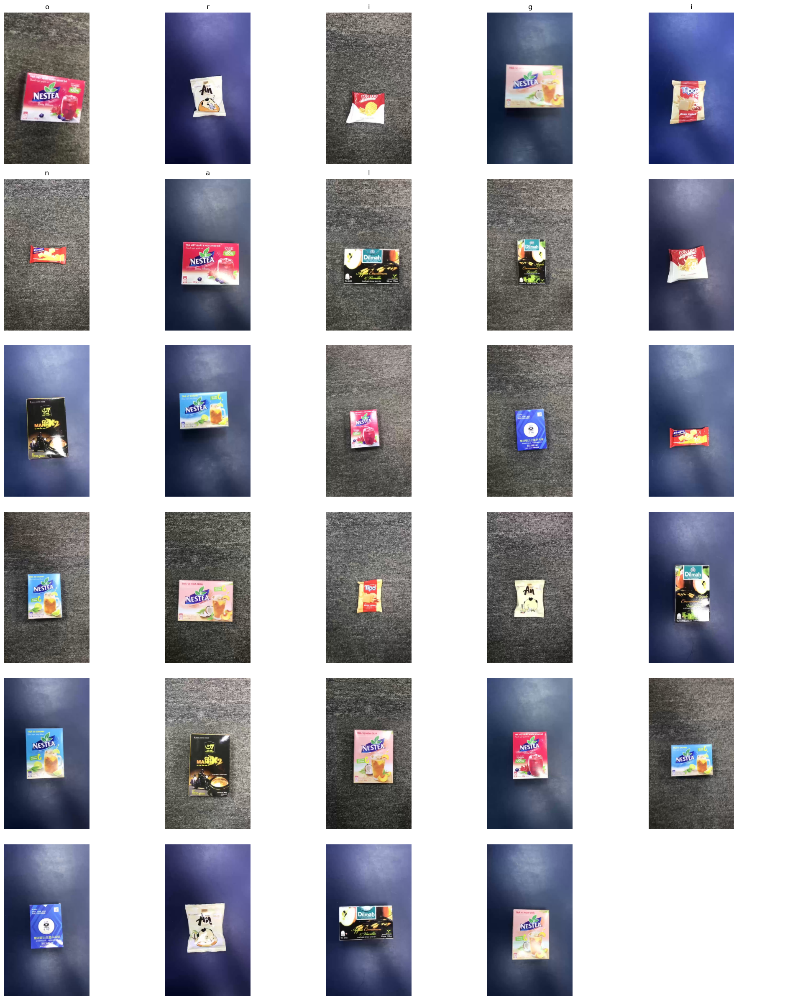

In [305]:
samples_mat = []
for i in range(len(samples_list)):
    samples_mat.append(cv2.imread(samples_list[i]))
    h, w = samples_mat[i].shape[:2]
    if w > h:
        samples_mat[i]=cv2.rotate(samples_mat[i], cv2.ROTATE_90_CLOCKWISE)
plot_images(samples_mat, cols=5 , titles="original")

In [306]:
samples_mat_hsv = []
for i in range(len(samples_mat)):
    samples_mat_hsv.append(cv2.cvtColor(samples_mat[i], code=cv2.COLOR_BGR2HSV))

In [310]:
samples_mat_s = []
samples_mat_v = []
for hsv in samples_mat_hsv:
    samples_mat_s.append(hsv[:,:,1])
    samples_mat_v.append(hsv[:,:,2])

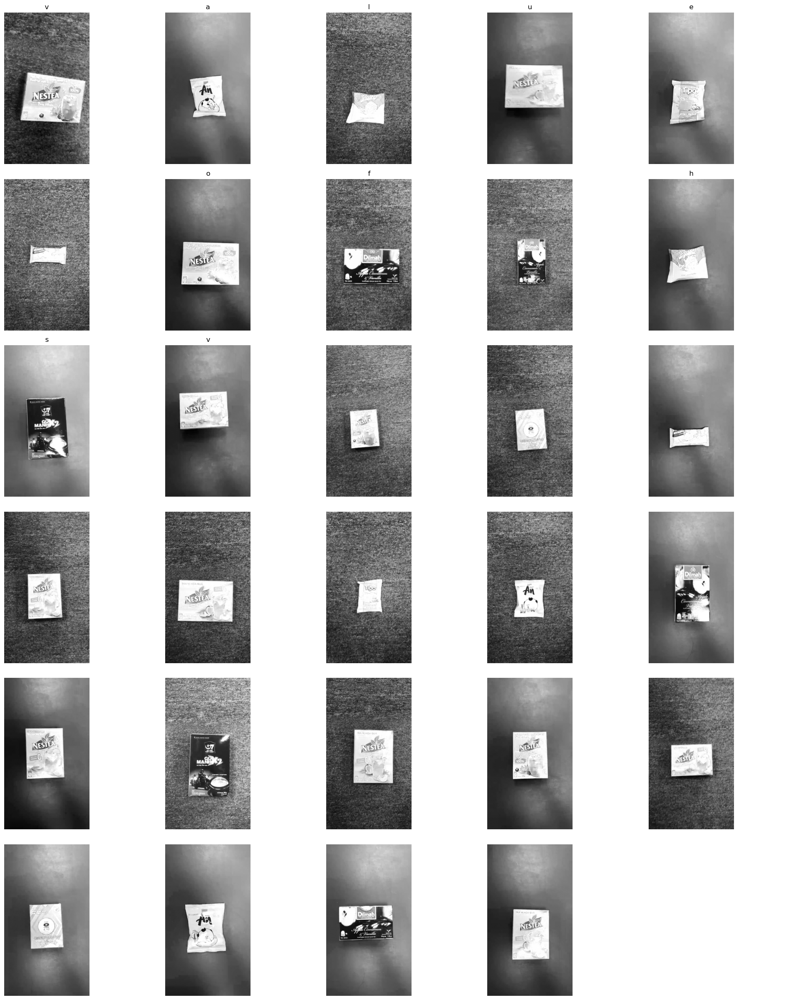

In [308]:
plot_images(samples_mat_v, cols=5, titles="value of hsv")

### g7 need inversion cause of its pure black appearance

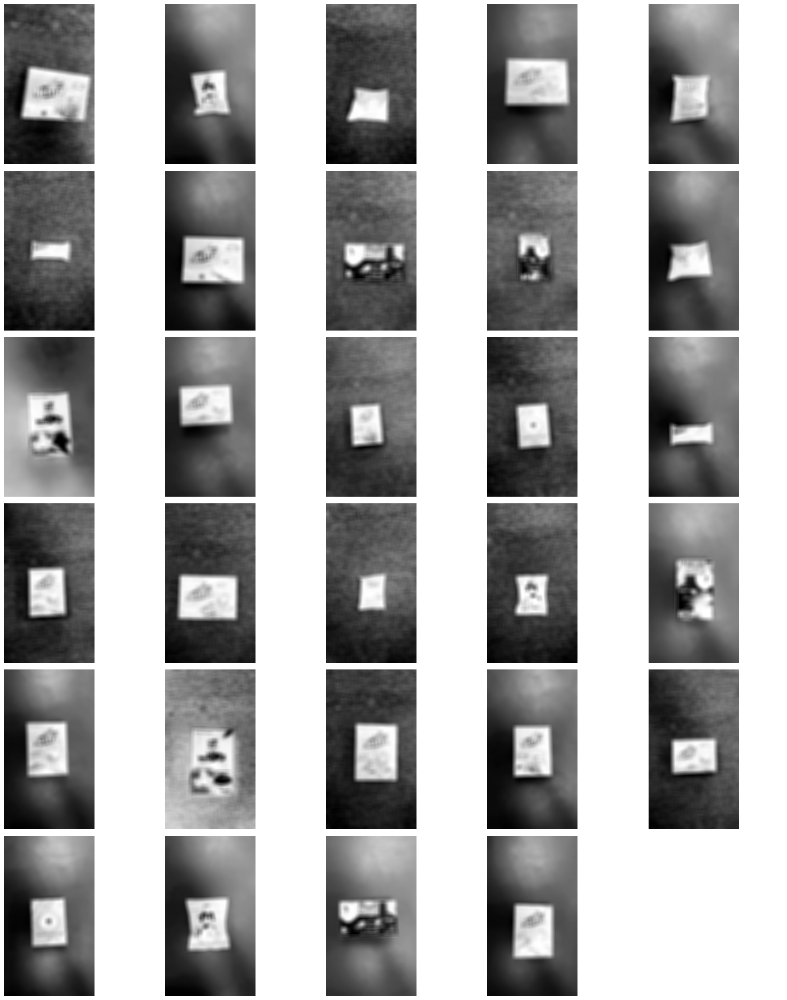

In [311]:
samples_mat_v_box_filtered = []
g7_index = [10,21]
for i in range(len(samples_mat_v)):
    if i in g7_index:
        samples_mat_v[i] = 255-samples_mat_v[i]
    samples_mat_v_box_filtered.append(cv2.blur(samples_mat_v[i], (43,43)))

plot_images(samples_mat_v_box_filtered, cols=5)

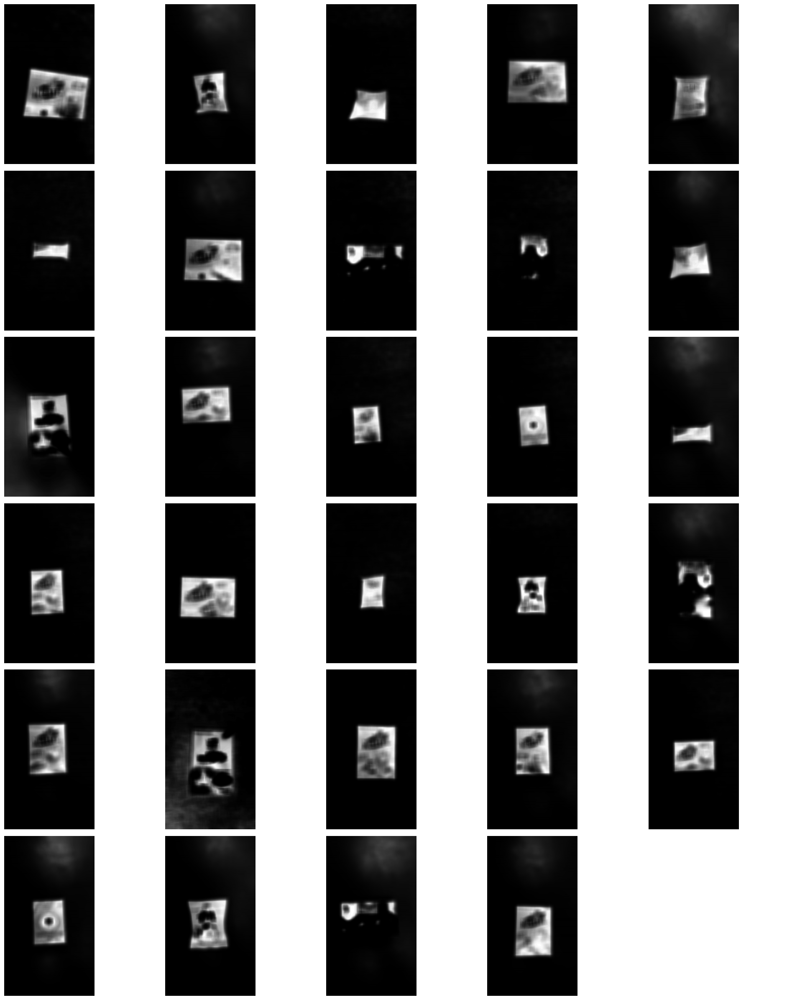

In [312]:
gamma = 6.0  # Values > 1 darken lows much more than highs

# Build 256-element LUT
table = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)]).astype(np.uint8)

# Fast O(1) per-pixel mapping
samples_mat_box_filtered_gamma_correction = []
for i in range(len(samples_mat_v_box_filtered)):
    samples_mat_box_filtered_gamma_correction.append(cv2.LUT(samples_mat_v_box_filtered[i], table))
plot_images(samples_mat_box_filtered_gamma_correction, cols=5)

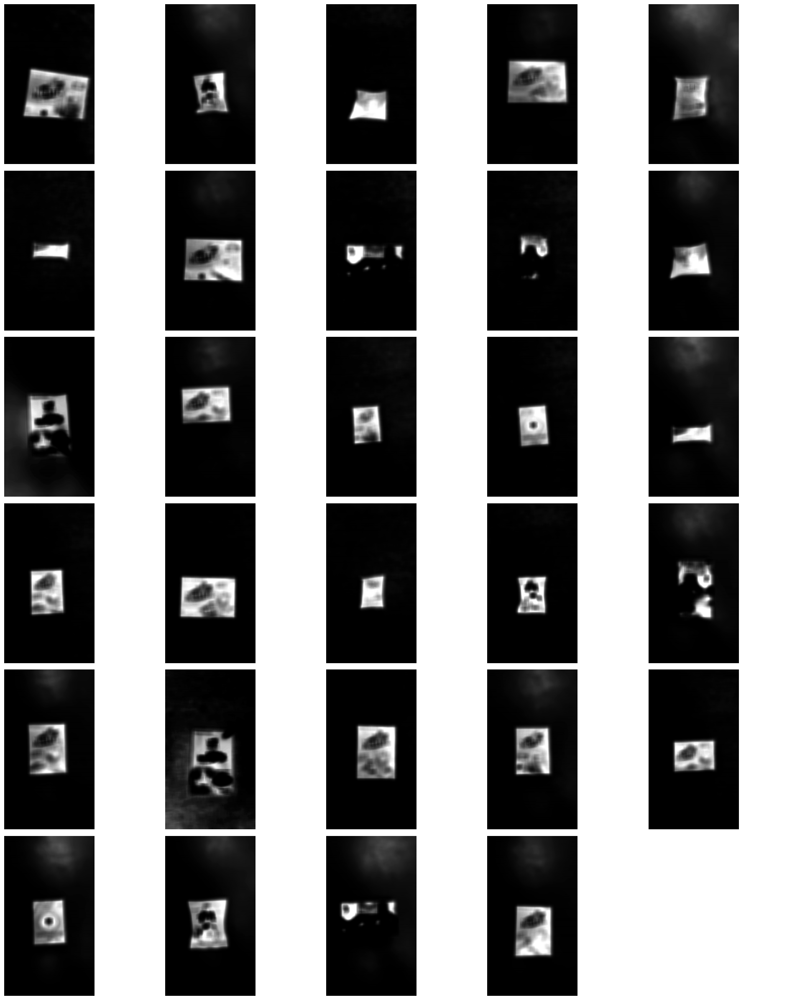

In [313]:
samples_mat_v_box_filtered_gamma_correction_enhance_contrast = []
for i in range(len(samples_mat_v)):
    samples_mat_v_box_filtered_gamma_correction_enhance_contrast.append(cv2.convertScaleAbs(samples_mat_box_filtered_gamma_correction[i], alpha=1.1, beta=0.0))
plot_images(samples_mat_v_box_filtered_gamma_correction_enhance_contrast, cols=5)

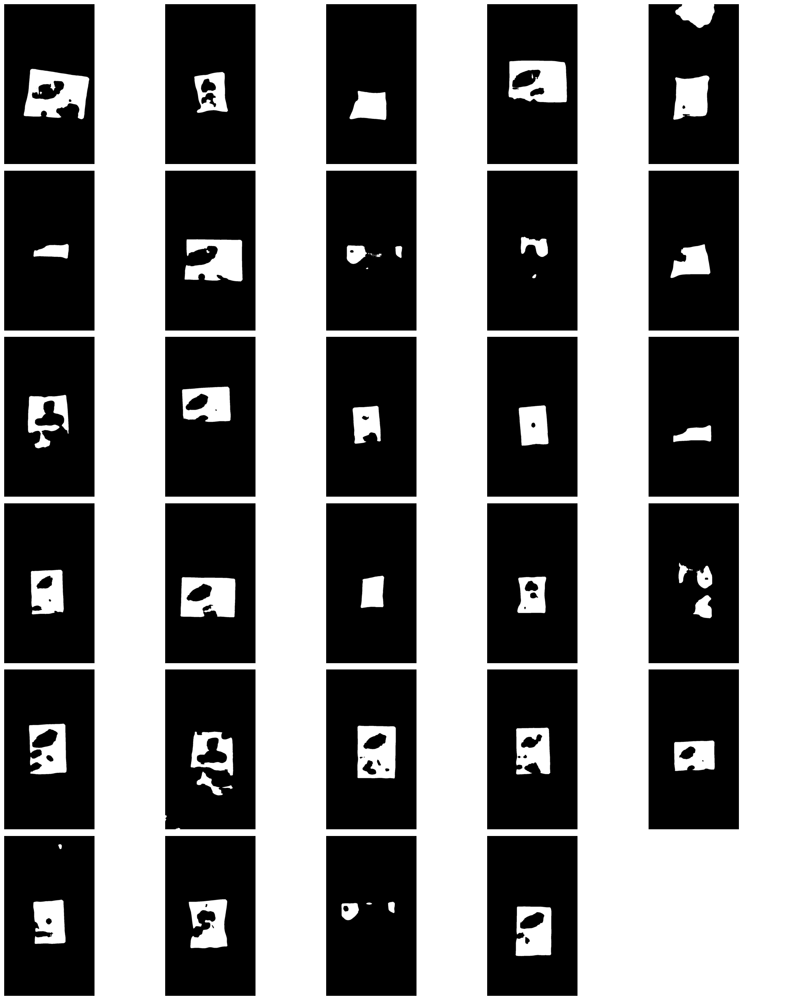

In [314]:
v_box_filtered_gamma_correction_enhance_contrast_binary = []
for i in range(len(samples_mat)):
    _, bin = cv2.threshold(samples_mat_v_box_filtered_gamma_correction_enhance_contrast[i], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    v_box_filtered_gamma_correction_enhance_contrast_binary.append(bin)
plot_images(v_box_filtered_gamma_correction_enhance_contrast_binary, cols=5)

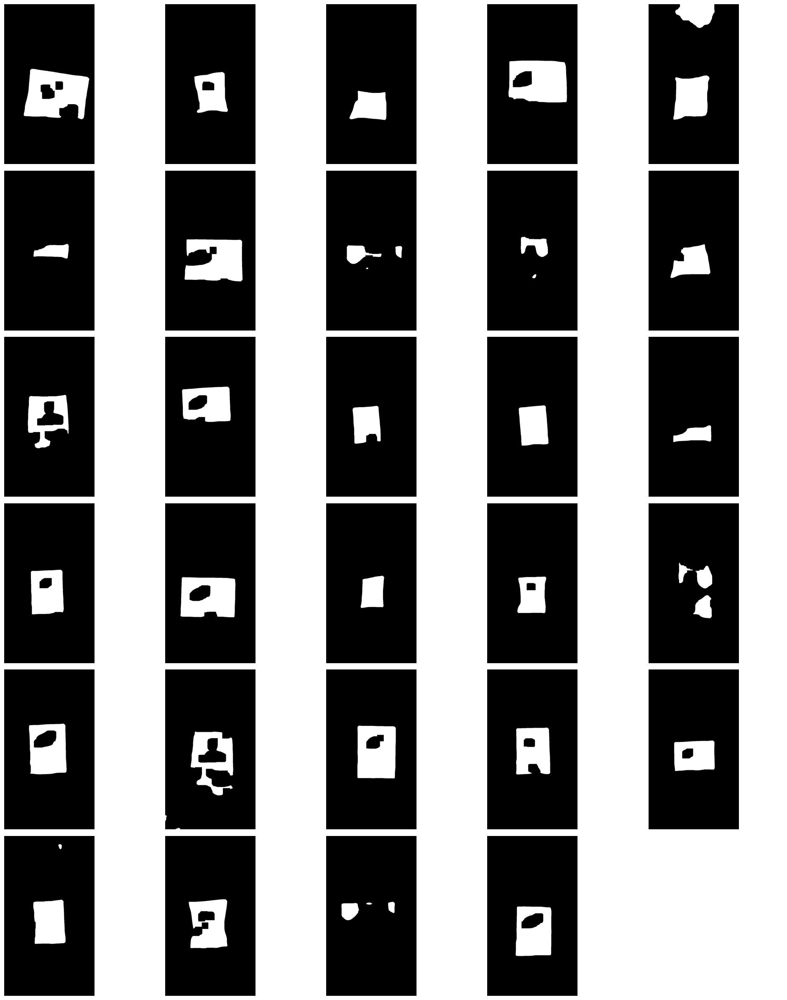

In [315]:
v_box_filtered_gamma_correction_enhance_contrast_binary_dilated = []
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (51,51))
for i in range(len(samples_mat)):
    v_box_filtered_gamma_correction_enhance_contrast_binary_dilated.append(cv2.morphologyEx(v_box_filtered_gamma_correction_enhance_contrast_binary[i], cv2.MORPH_CLOSE, kernel_close))
plot_images(v_box_filtered_gamma_correction_enhance_contrast_binary_dilated, cols=5)

In [316]:
final_boxes = []
padding_percentage_x = 0.05
padding_percentage_y = 0.2
for bin in v_box_filtered_gamma_correction_enhance_contrast_binary_dilated:
    h, w = bin.shape[:2]
    contours, _ = cv2.findContours(bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    valid_contours = []
    for cnt in contours:
        x, y, bw, bh = cv2.boundingRect(cnt)
        margin_x = 0.05*w
        margin_y = 0.1*h
        touches_border = (x <= margin_x or y <= margin_y or 
                          (x + bw) >= w - margin_x or (y + bh) >= h - margin_y)
        if not touches_border:
            valid_contours.append(cnt)
    
    hull = cv2.convexHull(np.vstack(valid_contours))
    x,y,bw,bh = cv2.boundingRect(hull)
    padding_x = int(min(x, w-x-bw)*padding_percentage_x)
    padding_y = int(min(y, h-y-bh)*padding_percentage_y)
    final_boxes.append((x-padding_x,y-padding_y,bw+2*padding_x,bh+2*padding_y))

### dilmah need y padding down 0.2, all other need padding left and right 0.05

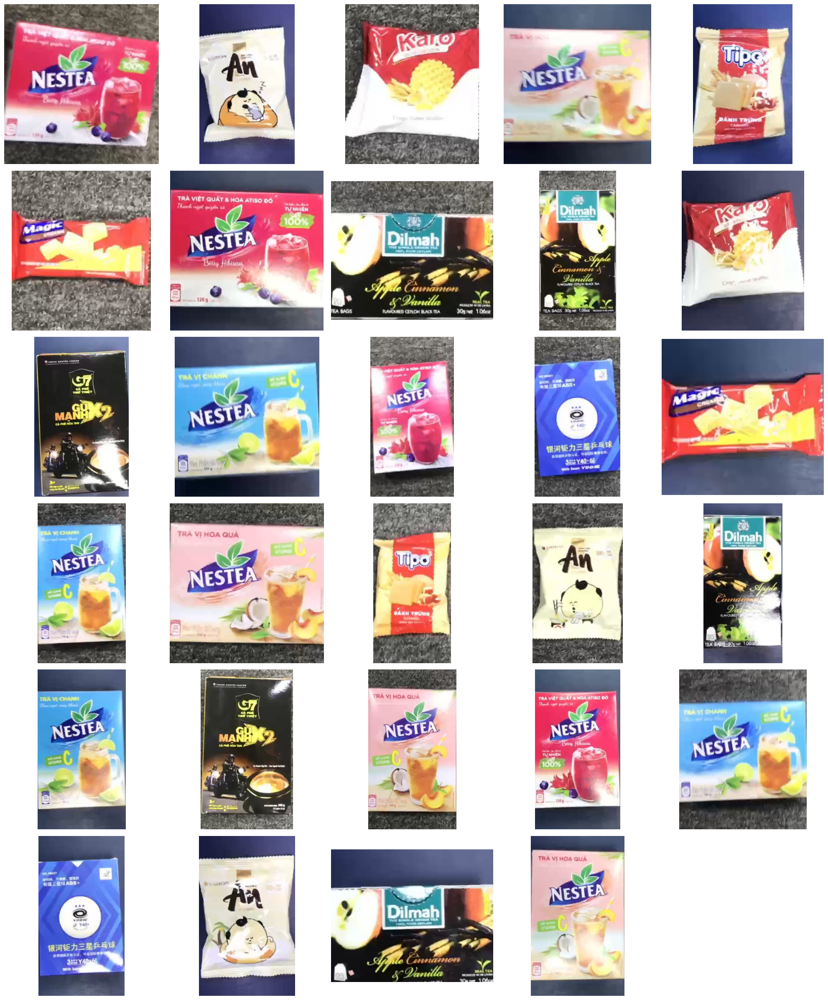

In [317]:
cropped_images = []
h,w = samples_mat[0].shape[:2]
for i in range(len(samples_mat)):
    x,y,w,h = final_boxes[i]
    crop = samples_mat[i][y:y+h,x:x+w,:]
    cropped_images.append(crop)
plot_images(cropped_images, cols=5)

In [4]:
from typing import List, Union

def process_image_mat(
    img_bgr: np.ndarray, g7: bool = False, dilmah: bool = False
) -> np.ndarray:
    """Preprocesses a single loaded BGR image, detects the object bounding box,

    applies custom padding, resizes so the max dimension is 224, and
    letterboxes with black border to 224x224.
    """
    # 1. Orientation check: if w > h, rotate 90 degrees clockwise
    h, w = img_bgr.shape[:2]
    if w > h:
        img_bgr = cv2.rotate(img_bgr, cv2.ROTATE_90_CLOCKWISE)

    orig_h, orig_w = img_bgr.shape[:2]

    # 2. Convert to HSV and extract V channel
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    v_channel = hsv[:, :, 2]

    # 3. G7 inversion condition
    if g7:
        v_channel = 255 - v_channel

    # 4. Blur filter (43x43 kernel)
    v_blurred = cv2.blur(v_channel, (43, 43))

    # 5. Gamma correction (gamma = 6.0)
    gamma = 6.0
    gamma_table = np.array(
        [((i / 255.0) ** gamma) * 255 for i in range(256)], dtype=np.uint8
    )
    v_gamma = cv2.LUT(v_blurred, gamma_table)

    # 6. Contrast enhancement (alpha = 1.1, beta = 0.0)
    v_enhanced = cv2.convertScaleAbs(v_gamma, alpha=1.1, beta=0.0)

    # 7. Otsu's binary thresholding
    _, binary_mask = cv2.threshold(
        v_enhanced, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # 8. Morphological closing (51x51 rectangular kernel)
    kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (51, 51))
    binary_closed = cv2.morphologyEx(
        binary_mask, cv2.MORPH_CLOSE, kernel_close
    )

    # 9. Find contours and filter border-touching contours
    contours, _ = cv2.findContours(
        binary_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    margin_x = 0.05 * orig_w
    margin_y = 0.10 * orig_h

    valid_contours = []
    for cnt in contours:
        bx, by, bw, bh = cv2.boundingRect(cnt)
        touches_border = (
            bx <= margin_x
            or by <= margin_y
            or (bx + bw) >= orig_w - margin_x
            or (by + bh) >= orig_h - margin_y
        )
        if not touches_border:
            valid_contours.append(cnt)

    # Fallback if all contours were filtered out
    if len(valid_contours) == 0:
        if len(contours) > 0:
            valid_contours = [max(contours, key=cv2.contourArea)]
        else:
            valid_contours = [
                np.array(
                    [
                        [[int(orig_w * 0.2), int(orig_h * 0.2)]],
                        [[int(orig_w * 0.8), int(orig_h * 0.8)]],
                    ]
                )
            ]

    # 10. Convex Hull bounding box
    all_pts = np.vstack(valid_contours)
    hull = cv2.convexHull(all_pts)
    bx, by, bw, bh = cv2.boundingRect(hull)

    # 11. Padding:
    # 5% of min(left, right) for both X sides
    # 5% of min(top, bottom) for top; 20% (dilmah) or 5% (normal) for bottom
    space_left = max(0, bx)
    space_right = max(0, orig_w - (bx + bw))
    space_top = max(0, by)
    space_bottom = max(0, orig_h - (by + bh))

    min_space_x = min(space_left, space_right)
    min_space_y = min(space_top, space_bottom)
    
    pad_left = int(min_space_x * 0.05)
    pad_right = int(min_space_x * 0.05)
    pad_top = int(min_space_y * 0.05)
    pad_bottom = int(min_space_y * (0.20 if dilmah else 0.05))
    
    x1 = max(0, bx - pad_left)
    y1 = max(0, by - pad_top)
    x2 = min(orig_w, bx + bw + pad_right)
    y2 = min(orig_h, by + bh + pad_bottom)

    crop = img_bgr[y1:y2, x1:x2]
    crop_h, crop_w = crop.shape[:2]

    # 12. Aspect-ratio preserving resize so max dimension is 224
    target_dim = 224
    scale = target_dim / max(crop_h, crop_w)
    new_w = max(1, round(crop_w * scale))
    new_h = max(1, round(crop_h * scale))

    # If smaller dimension is odd, round it to the nearest even number
    # so padding on both sides is 100% identical
    if new_w < target_dim and new_w % 2 != 0:
        new_w += 1
    if new_h < target_dim and new_h % 2 != 0:
        new_h += 1

    resized_crop = cv2.resize(
        crop, (new_w, new_h), interpolation=cv2.INTER_AREA
    )

    # 13. Letterbox on 224x224 black canvas
    square_img = np.zeros((target_dim, target_dim, 3), dtype=np.uint8)
    pad_offset_x = (target_dim - new_w) // 2
    pad_offset_y = (target_dim - new_h) // 2

    square_img[
        pad_offset_y : pad_offset_y + new_h, pad_offset_x : pad_offset_x + new_w
    ] = resized_crop

    return square_img


def process_images_from_folders(
    input_folders: Union[List[str], str],
    output_folder: str,
    g7: bool = False,
    dilmah: bool = False,
    prefix: str = "frame",
    start_index: int = 0,
    valid_extensions: tuple = (
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".webp",
        ".tiff",
    ),
) -> List[str]:
    """Loops through all given input folders, collects all image file paths,

    processes and crops each image, and saves them to the output folder with a
    sequential, zero-padded numbering scheme (e.g., `frame_000000.jpg`).

    Args:
        input_folders (List[str] or str): Folder path or list of folder paths to
          scan.
        output_folder (str): Directory where processed images will be saved.
        g7 (bool): If True, invert V channel (255 - V).
        dilmah (bool): If True, bottom y-padding is 0.20, else 0.05.
        prefix (str): Prefix for the saved filenames (default: 'frame').
        start_index (int): Initial number for the counter (default: 0).
        valid_extensions (tuple): Allowed image file extensions (lowercase).

    Returns:
        List[str]: List of paths to all successfully saved output images.
    """
    if isinstance(input_folders, (str, Path)):
        input_folders = [input_folders]

    out_dir = Path(output_folder)
    out_dir.mkdir(parents=True, exist_ok=True)

    # 1. Gather all image paths across all input folders
    image_paths: List[Path] = []
    for folder in input_folders:
        f_path = Path(folder)
        if not f_path.is_dir():
            print(f"Warning: Folder does not exist or is not a directory: {folder}")
            continue

        # Sort files inside each folder for deterministic order
        for file in sorted(f_path.iterdir()):
            if file.is_file() and file.suffix.lower() in valid_extensions:
                image_paths.append(file)

    total_images = len(image_paths)
    print(
        f"Found {total_images} images across {len(input_folders)} folder(s)."
    )

    # Determine padding width: at least 6 digits (000000), or more if > 1,000,000 images
    pad_width = max(6, len(str(start_index + total_images)))

    saved_filepaths: List[str] = []
    current_index = start_index

    # 2. Process each image
    for idx, img_path in enumerate(image_paths):
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            print(f"Warning: Could not read image {img_path}, skipping.")
            continue

        try:
            processed_img = process_image_mat(img_bgr, g7=g7, dilmah=dilmah)

            # File naming formatting e.g. frame_000000.jpg
            out_filename = f"{prefix}_{current_index:0{pad_width}d}.jpg"
            out_path = out_dir / out_filename

            cv2.imwrite(str(out_path), processed_img)
            saved_filepaths.append(str(out_path))

            current_index += 1

            if (idx + 1) % 100 == 0 or (idx + 1) == total_images:
                print(f"Processed [{idx + 1}/{total_images}] images...")

        except Exception as e:
            print(f"Error processing {img_path}: {e}")

    print(
        f"Completed: Saved {len(saved_filepaths)} images to '{output_folder}'."
    )
    return saved_filepaths


In [11]:
output_folder = "/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40"
target_dir = Path("/home/filelele/personal_project/belt-conveyor-object-count/dataset/raw_frames/cellphone_video_for_train/y40")
input_folders = [str(p) for p in target_dir.iterdir() if p.is_dir()]
process_images_from_folders(input_folders, output_folder)

Found 989 images across 2 folder(s).
Processed [100/989] images...
Processed [200/989] images...
Processed [300/989] images...
Processed [400/989] images...
Processed [500/989] images...
Processed [600/989] images...
Processed [700/989] images...
Processed [800/989] images...
Processed [900/989] images...
Processed [989/989] images...
Completed: Saved 989 images to '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40'.


['/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40/frame_000000.jpg',
 '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40/frame_000001.jpg',
 '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40/frame_000002.jpg',
 '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40/frame_000003.jpg',
 '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40/frame_000004.jpg',
 '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40/frame_000005.jpg',
 '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40/frame_000006.jpg',
 '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40/frame_000007.jpg',
 '/home/filelele/personal_project/belt-conveyor-object-count/dataset/cropped_frames/y40/frame_000008.jpg',
 '/home/filelele/personal_project/bel